In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.table import Table

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dense

### Load data

In [10]:
with fits.open("../data/20260807/20260807_RT1.fits") as hdul:
    RT1 = Table(hdul[1].data).to_pandas()
print(RT1.shape)

(215223, 22)


### Plot raw data

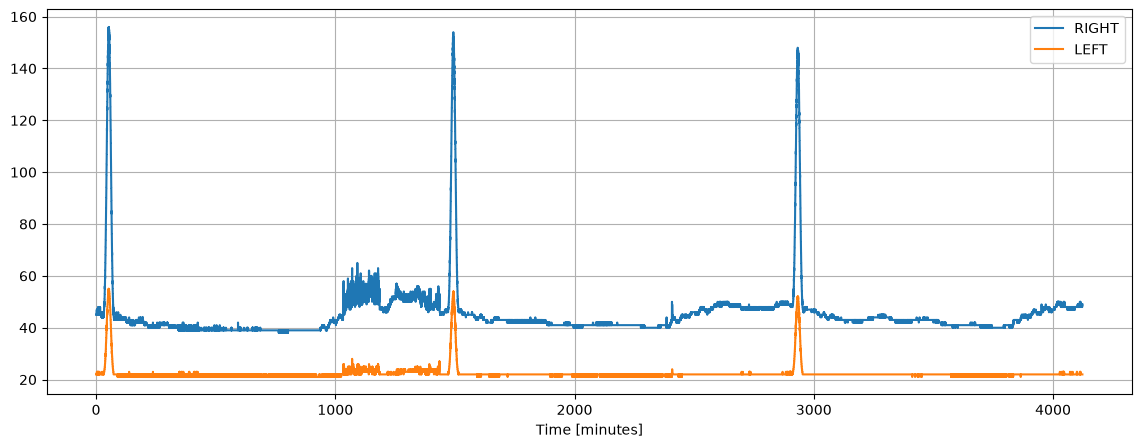

In [14]:
time_minutes = (
    RT1["JD"]
    -
    RT1["JD"].iloc[0]
) * 24 * 60

plt.figure(figsize=(14,5))

plt.plot(
    time_minutes,
    RT1["RIGHT_POL"],
    label="RIGHT"
)

plt.plot(
    time_minutes,
    RT1["LEFT_POL"],
    label="LEFT"
)

plt.xlabel("Time [minutes]")

#plt.xlim(0,200)

plt.legend()
plt.grid()

plt.show()

### Normalise the polarisations

In [15]:
right = (
    RT1["RIGHT_POL"]
    -
    RT1["RIGHT_POL"].median()
) / RT1["RIGHT_POL"].std()

left = (
    RT1["LEFT_POL"]
    -
    RT1["LEFT_POL"].median()
) / RT1["LEFT_POL"].std()

### Compute sampling intervals

In [17]:
jd = RT1["JD"].values

dt = np.diff(jd)

dt = np.insert(
    dt,
    0,
    np.median(dt)
)

# convert to seconds
dt = dt * 86400.0

#normalise dt
dt = (
    dt - np.median(dt)
) / np.std(dt)

### Set window length

In [18]:
window = 50

### Build LSTM dataset

In [19]:
X = []
y = []

jd_target = []

for i in range(window, len(RT1)):

    left_seq = (
        left.iloc[i-window:i]
        .values
    )

    dt_seq = (
        dt[i-window:i]
    )

    sequence = np.column_stack([
        left_seq,
        dt_seq
    ])

    X.append(sequence)

    y.append(
        right.iloc[i]
    )

    jd_target.append(
        RT1["JD"].iloc[i]
    )

X = np.array(X)

y = np.array(y)

jd_target = np.array(jd_target)

In [22]:
#check shape to be (N, 50, 2)
# N samples, 50 timesteps, 2 features
print(X.shape)

(215173, 50, 2)


### Train / Test split

In [23]:
split = int(
    0.8 * len(X)
)

X_train = X[:split]
X_test  = X[split:]

y_train = y[:split]
y_test  = y[split:]

jd_test = jd_target[split:]

### Build LSTM

In [25]:
model = Sequential()

model.add(
    LSTM(
        32,
        input_shape=(window, 2)
    )
)

model.add(
    Dense(1)
)

model.compile(
    optimizer="adam",
    loss="mse"
)

### Train

In [26]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=256,
    verbose=1
)

Epoch 1/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - loss: 0.0654 - val_loss: 0.2283
Epoch 2/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.0055 - val_loss: 0.2447
Epoch 3/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - loss: 0.0048 - val_loss: 0.2348
Epoch 4/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.0047 - val_loss: 0.2380
Epoch 5/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.0045 - val_loss: 0.2374
Epoch 6/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.0044 - val_loss: 0.2460
Epoch 7/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - loss: 0.0044 - val_loss: 0.2492
Epoch 8/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.0043 - val_loss: 0.2446
Epoch 9/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.0041 - val_loss: 0.2479
Epoch 10/10
606/606 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 0.0041 - val_loss: 0.2533


### Predict

In [27]:
pred = (
    model
    .predict(X_test)
    .flatten()
)

1345/1345 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


### Plot Results

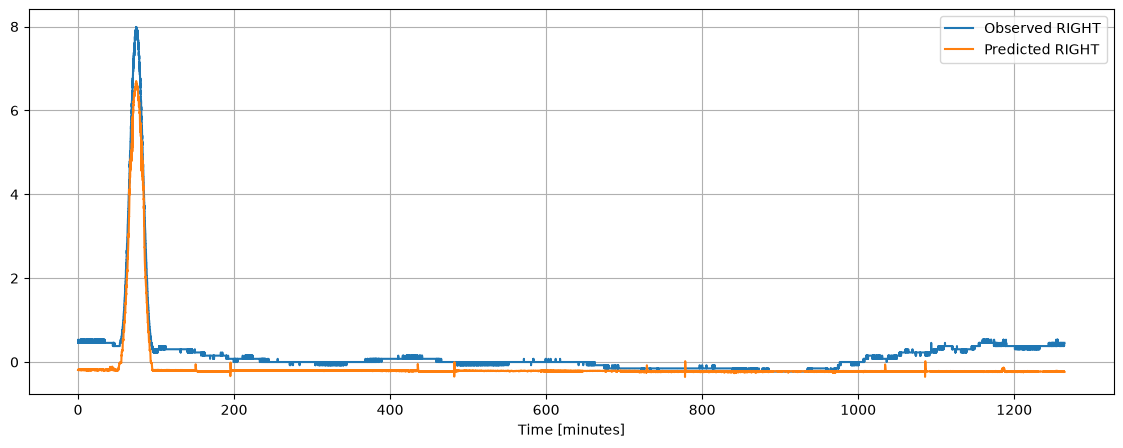

In [30]:
time_minutes = (
    jd_test -
    jd_test[0]
) * 24 * 60

plt.figure(figsize=(14,5))

plt.plot(
    time_minutes,
    y_test,
    label="Observed RIGHT"
)

plt.plot(
    time_minutes,
    pred,
    label="Predicted RIGHT"
)

plt.legend()
plt.grid()

plt.xlabel("Time [minutes]")

plt.show()

### Residuals

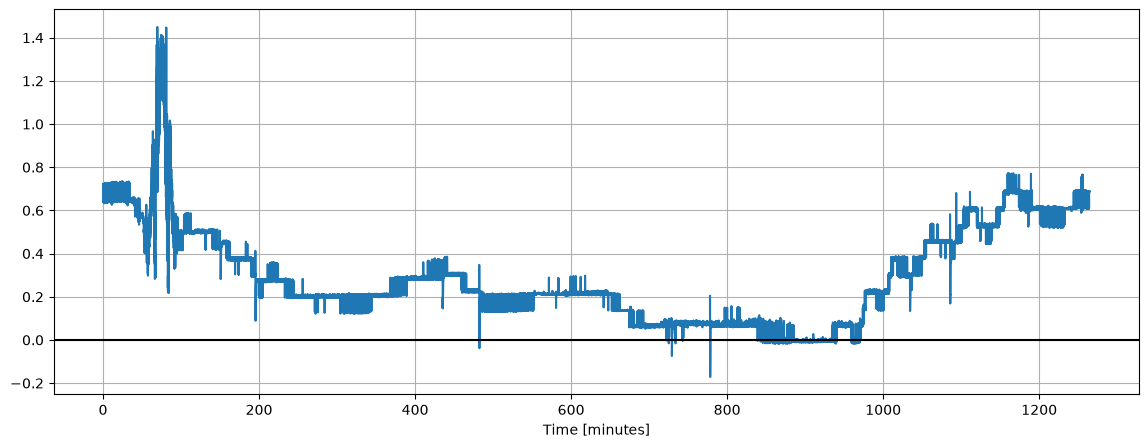

In [32]:
residual = (
    y_test
    -
    pred
)


plt.figure(figsize=(14,5))

plt.plot(
    time_minutes,
    residual
)

plt.axhline(
    0,
    color="black"
)

plt.grid()

plt.xlabel("Time [minutes]")

plt.show()

### Anomaly detection

In [47]:
sigma = residual.std()

anomaly = (
    np.abs(residual)
    >
    1.5*sigma
)

print(
    "Number of anomalies:",
    anomaly.sum()
)

Number of anomalies: 14043


### Plot anomalies on original RIGHT polarization.

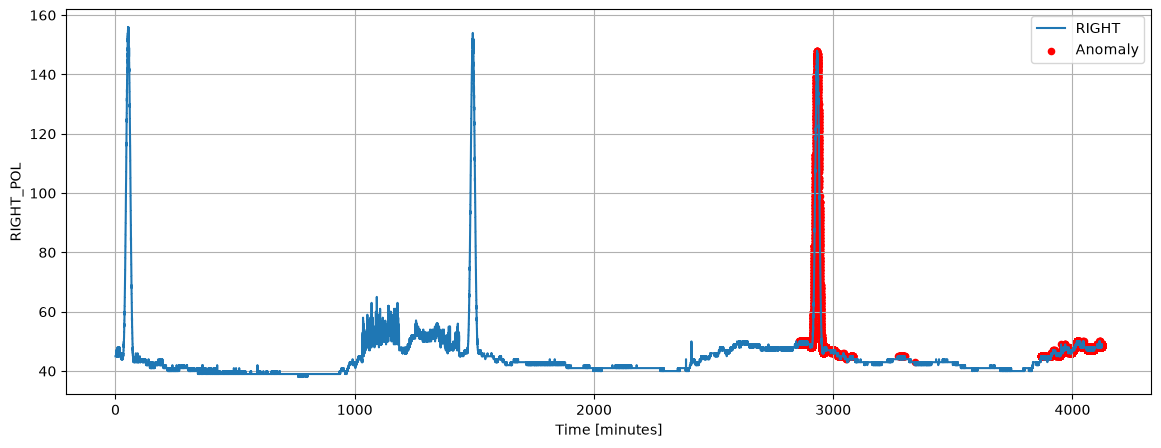

In [48]:
full_time_minutes = (
    RT1["JD"]
    -
    RT1["JD"].iloc[0]
) * 24 * 60

test_indices = np.arange(
    split + window,
    len(RT1)
)

plt.figure(figsize=(14,5))

plt.plot(
    full_time_minutes,
    RT1["RIGHT_POL"],
    label="RIGHT"
)

plt.scatter(
    full_time_minutes.iloc[
        test_indices[anomaly]
    ],
    RT1["RIGHT_POL"].iloc[
        test_indices[anomaly]
    ],
    color="red",
    s=20,
    label="Anomaly"
)

plt.xlabel("Time [minutes]")
plt.ylabel("RIGHT_POL")

plt.legend()
plt.grid()

plt.show()

In [7]:
dt = np.diff(RT1["JD"])

print(np.min(dt))
print(np.median(dt))
print(np.max(dt))

4.270579665899277e-06
1.2268312275409698e-05
6.692111492156982e-05


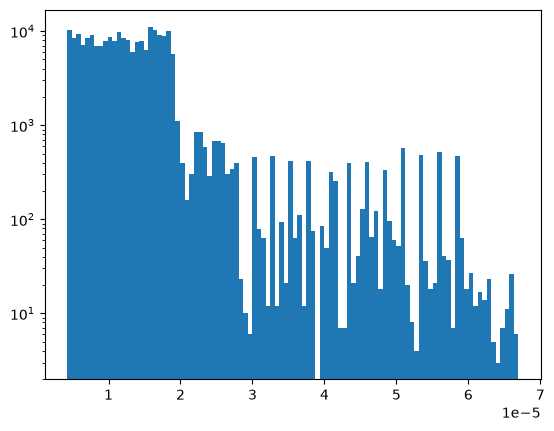

In [8]:
plt.hist(dt, bins=100)
plt.yscale("log")
plt.show()